<a href="https://colab.research.google.com/github/M-AyyanAsif/NETSOL_TASKS/blob/main/decision_tree_worksheet_updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🌳 Decision Trees and Random Forest — Hands-On Worksheet
### Updated to match Lecture 19: from one tree that can be fooled to a forest that votes

---

### 📌 What You Will Practise

| Concept | What it means in plain English | Slides |
|---|---|---|
| **Gini mix-up score** | A number for "how mixed is this group?" (low = clean) | Which question first? |
| **Reading a tree** | Follow the yes/no boxes to an answer | A tree learned from the 20 people |
| **Overfitting** | A tree that never stops memorises | A tree that never stops memorises |
| **The brakes** | `max_depth`, `min_samples_leaf`, pruning | How to stop a tree |
| **Random forest** | Many different trees, one vote | Ask many trees, then vote |
| **Boosting** *(bonus)* | A team that fixes each other's mistakes | Boosting |
| **Entropy** *(bonus)* | Another mix-up score, used by the older ID3 algorithm | Optional entropy slide |

### 🌍 Datasets We Use
| Dataset | What it is | Problem |
|---|---|---|
| **Salary data** | The same 20 people as the lecture | Is this person a **High earner** (salary ≥ $55k)? |
| **Iris flowers** | 150 flowers, 4 measurements | Which of 3 species is this flower? |
| **Customer survey** (`customer_survey.csv`) | 11,805 customers (the file from the SVM lab) | Satisfied or Dis Satisfied? |
| **Breast cancer** | 569 patients, 30 measurements | Malignant or benign? |
| **Diabetes** *(bonus)* | 442 patients, 10 measurements | How fast does the disease progress? |

### 🗺️ The Plan
| Part | Tasks | Focus |
|---|---|---|
| **Part 1 — Salary data** | Tasks 1–4 | Gini by hand, a first tree, memorising, the first brake |
| **Part 2 — Iris** | Task 5 | Read a real tree and its feature importances |
| **Part 3 — Real-size data** | Tasks 6–8 | Overfitting, the brakes, and the forest |

**Core work = Tasks 1–8.** The four ⭐ bonus tasks are for fast finishers.

### 📋 How to work through this
- Read each **Background**, then do the **Steps** in the code cell
- Cells with `___` are blanks for you to fill in. A cell with blanks will give an error until you complete it
- **💬 Think About It** boxes have questions: write your answers in your notes
- Trees need **no scaling**, so there is no `StandardScaler` anywhere in this worksheet

---

In [5]:
# ╔═══════════════════════════════════════╗
# ║  RUN THIS CELL FIRST — every time!   ║
# ╚═══════════════════════════════════════╝
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.datasets import load_iris, load_breast_cancer, load_diabetes
from sklearn.metrics import accuracy_score, confusion_matrix, mean_squared_error, r2_score

np.random.seed(42)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

# ── The salary table from the lecture (20 people) ───────────────────────────
salary_columns = ['experience', 'education', 'age', 'certifications', 'salary']
salary_rows = [      # experience, education, age, certifications, salary ($k)
    (1,16,23,0,35), (2,16,24,1,40), (3,18,26,1,47), (4,16,27,2,51),
    (5,18,29,2,58), (6,18,31,3,62), (7,20,33,3,70), (8,20,35,4,75),
    (1,18,24,1,42), (2,20,26,2,52), (3,16,25,0,41), (4,20,28,3,60),
    (5,16,30,1,53), (6,16,32,1,56), (7,18,31,2,66), (8,16,36,2,64),
    (9,20,34,4,82), (10,18,38,3,80), (2,16,22,0,36), (9,16,40,1,68),
]
HI, LO = '#2E8B57', '#B23A48'      # green square = High earner, red circle = Not high

def person(exp, certs):
    """One new person as a one-row table, so scikit-learn sees the column names."""
    return pd.DataFrame([[exp, certs]], columns=['experience', 'certifications'])

def load_csv(name):
    """Read a CSV that sits next to this notebook. In Colab, shows an upload box if it is missing."""
    if not os.path.exists(name):
        try:
            from google.colab import files
            print(f'📂 {name} not found — choose it in the upload box below')
            files.upload()
        except ImportError:
            raise FileNotFoundError(f'{name} not found. Put it in the same folder as this notebook.')
    return pd.read_csv(name)

print('✅ Ready to go!')
print(f'  Salary table : {len(salary_rows)} people, columns = {salary_columns}')
print('  customer_survey.csv: ' + ('found ✅' if os.path.exists('customer_survey.csv') else 'not uploaded yet (needed from Task 6 on)'))

✅ Ready to go!
  Salary table : 20 people, columns = ['experience', 'education', 'age', 'certifications', 'salary']
  customer_survey.csv: not uploaded yet (needed from Task 6 on)


---
---
# 💼 PART 1 — The Salary Data
## "Is this person a High earner?" — now answered by a chain of yes/no questions

Same 20 people as before. With only 20 dots and 2 columns you can **check every number by hand**, which is the best way to understand what a tree really does.

---

---
## ✏️ Task 1 — Look Before You Train: The Salary Data

### Background
A tree needs a **label**, the "right answer" it learns from. Here the label is **High earner = salary of $55k or more**.

We use two columns: `experience` (years) and `certifications`. We also mark the **tricky person** from the lectures: 3 years of experience and 4 certifications. Different methods gave different answers for this person, so let us see what trees say.

### Steps
1. Build a DataFrame `df` from `salary_rows` with the column names in `salary_columns`
2. Add a column `high_earner` that is `1` when salary ≥ 55 and `0` otherwise
3. Print how many High earners and how many Not high people there are
4. Create `X` (the columns `experience` and `certifications`) and `y` (the `high_earner` column)
5. Draw a scatter plot: green squares for High earners, red circles for Not high, and a gold star for the tricky person (3, 4)

,experience,education,age,certifications,salary,high_earner
person,,,,,,
1,1,16,23,0,35,0
2,2,16,24,1,40,0
3,3,18,26,1,47,0
4,4,16,27,2,51,0
5,5,18,29,2,58,1
6,6,18,31,3,62,1
7,7,20,33,3,70,1
8,8,20,35,4,75,1
9,1,18,24,1,42,0


High earners: 11 | Not high: 9


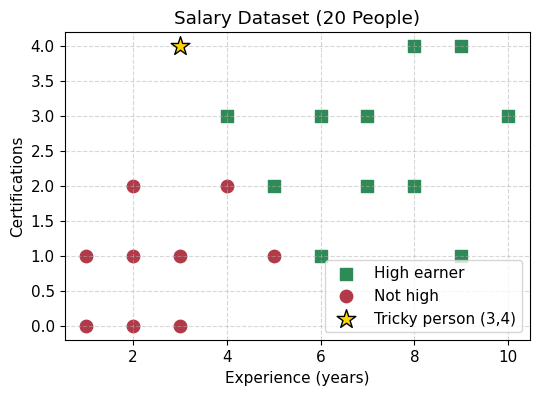

In [6]:
# ✏️ Fill in the blanks
df = pd.DataFrame(salary_rows, columns=salary_columns)          # salary_rows, salary_columns
df.index = df.index + 1                       # person numbers 1..20
df.index.name = 'person'
df['high_earner'] = (df['salary'] >= 55).astype(int)
display(df)

print('High earners:', (df['high_earner'] == 1).sum(), '| Not high:', (df['high_earner'] == 0).sum())

X = df[['experience', 'certifications']]       # the two columns we use
y = df['high_earner']              # the label

# Scatter plot: green square = High earner, red circle = Not high, gold star = tricky person (3, 4)
plt.figure(figsize=(6, 4))
# Plot high earners (y == 1)
high_mask = y == 1
plt.scatter(X.loc[high_mask, 'experience'], X.loc[high_mask, 'certifications'],
            color=HI, marker='s', s=80, label='High earner')
# Plot not high earners (y == 0)
not_high_mask = y == 0
plt.scatter(X.loc[not_high_mask, 'experience'], X.loc[not_high_mask, 'certifications'],
            color=LO, marker='o', s=80, label='Not high')
# Plot tricky person (3, 4)
plt.scatter(3, 4, color='gold', marker='*', s=200, edgecolor='black', zorder=5, label='Tricky person (3,4)')

plt.xlabel('Experience (years)')
plt.ylabel('Certifications')
plt.title('Salary Dataset (20 People)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**💬 Think About It:**

*Are the two groups balanced? What share is High?*  
*Where would you draw a vertical or a horizontal cut to separate the groups? Remember: a tree can only cut straight across one column.*

---
## ✏️ Task 2 — Gini by Hand: Which Question Should the Tree Ask First?

### Background
A good question leaves **clean groups**. We measure "how mixed is this group?" with the **Gini score**:

```
Gini = 1 − (share of High)² − (share of Not high)²
```

Low Gini = clean group. 0 means perfectly pure, and 0.5 is the worst possible mix of two groups.

To judge a question, compute the Gini of the **Yes side** and the **No side**, then average them, weighted by how many people are on each side. The tree tries **every column and every cut-off** and keeps the cleanest. You will play the tree now.

### Steps
1. Write a function `gini(n_high, n_not)` that returns the Gini score of a group
2. Print the Gini of three groups: all 20 people (11 High, 9 Not high), a group of 9 who are all High, and a group of 6 High and 6 Not high
3. Write `split_score(column, cut)`: the weighted average Gini after asking "is `column` ≤ `cut`?"
4. Check the three questions from slide 8: `experience ≤ 3.5`, `experience ≤ 5.5`, `certifications ≤ 2.5`
5. Try **every** cut for both columns (the halfway point between each pair of neighbouring values) and print the three best questions

> 💡 The halfway points between sorted neighbours: `(values[:-1] + values[1:]) / 2`  
> 💡 `y[left].sum()` counts the High earners in the Yes side; `(1 - y[left]).sum()` counts the Not high

In [7]:
# ✏️ Fill in the blanks
def gini(n_high, n_not):
    total = n_high + n_not
    if total == 0:
        return 0.0
    return 1 - (n_high / total) ** 2 - (n_not / total) ** 2

print('All 20 people      :', round(gini(11, 9), 3))
print('9 people, all High :', round(gini(9, 0), 3))
print('6 High, 6 Not high :', round(gini(6, 6), 3))

def split_score(column, cut):
    """Average Gini after asking: is <column> <= cut ?  (weighted by group size)"""
    left = df[column] <= cut
    n_left, n_right = left.sum(), (~left).sum()
    g_left  = gini(y[left].sum(), (1 - y[left]).sum())
    g_right = gini(y[~left].sum(), (1 - y[~left]).sum())
    return (n_left * g_left + n_right * g_right) / len(df)

for column, cut in [('experience', 3.5), ('experience', 5.5), ('certifications', 2.5)]:
    print(f'{column} <= {cut}: {split_score(column, cut):.3f}')

# Try every cut for both columns
results = []
for column in ['experience', 'certifications']:
    values = np.sort(df[column].unique())
    cuts = (values[:-1] + values[1:]) / 2
    for cut in cuts:             # halfway points between neighbouring values
        results.append((split_score(column, cut), column, cut))
results.sort()
print()
for score, column, cut in results[:3]:
    print(f'{column} <= {cut}  →  average Gini {score:.3f}')

All 20 people      : 0.495
9 people, all High : 0.0
6 High, 6 Not high : 0.5
experience <= 3.5: 0.169
experience <= 5.5: 0.164
certifications <= 2.5: 0.321

experience <= 5.5  →  average Gini 0.164
experience <= 3.5  →  average Gini 0.169
experience <= 4.5  →  average Gini 0.180


**💬 Think About It:**

*Which question wins? How narrow is the win over the runner-up?*  
*Why is a Gini of 0.5 the worst case for two groups?*  
*What would the tree do next inside the 11-person group that is still mixed?*

---
## ✏️ Task 3 — Grow Your First Tree and Follow the Boxes

### Background
Now let scikit-learn do what you just did by hand, over and over, to build a whole tree. We limit it to **two questions deep** (`max_depth=2`) so it stays readable.

Once built, predicting is instant: follow the boxes. Look closely at where the tricky person ends up.

### Steps
1. Create `DecisionTreeClassifier(max_depth=2, random_state=0)` and fit it on `X` and `y`
2. Print the tree as text with `export_text(tree, feature_names=list(X.columns))`
3. Draw it with `plot_tree` (use `class_names=["Not high", "High"]` and `filled=True`)
4. Predict the three people from slide 6: (8 yrs, 2 certs), (4 yrs, 1 cert) and the tricky person (3 yrs, 4 certs). Use `person(exp, certs)`
5. Find the leaf the tricky person lands in with `tree.apply(person(3, 4))`, and list **which people from the table** are in that same leaf

> 💡 `tree.predict(...)` returns `[0]` or `[1]` where 1 = High  
> 💡 `tree.apply(X)` tells you the leaf number for every person in `X`

|--- experience <= 5.50
|   |--- certifications <= 2.50
|   |   |--- class: 0
|   |--- certifications >  2.50
|   |   |--- class: 1
|--- experience >  5.50
|   |--- class: 1



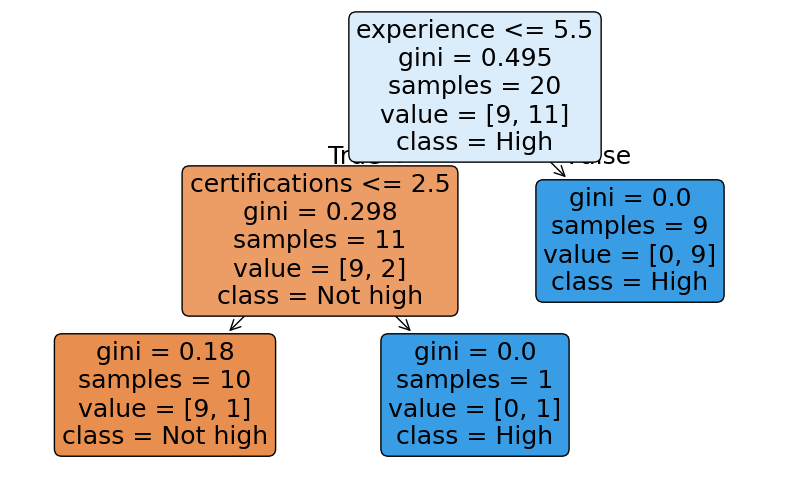

8 years, 2 certs  →   High
4 years, 1 certs  →   Not high
3 years, 4 certs  →   High
People in the tricky person's leaf: [np.int64(12)]


In [8]:
# ✏️ Fill in the blanks
tree = DecisionTreeClassifier(max_depth=2, random_state=0)
tree.fit(X, y)

print(export_text(tree, feature_names=list(X.columns)))

fig, ax = plt.subplots(figsize=(10, 6))
plot_tree(tree, feature_names=list(X.columns), class_names=['Not high', 'High'], filled=True, rounded=True, ax=ax)
plt.show()

# Predict the three people from slide 6
for exp, certs in [(8, 2), (4, 1), (3, 4)]:
    answer_idx = tree.predict(person(exp, certs))[0]
    answer = 'High' if answer_idx == 1 else 'Not high'
    print(f'{exp} years, {certs} certs  →  ', answer)      # print 'High' or 'Not high'

# Where does the tricky person land?
leaf = tree.apply(person(3, 4))[0]
in_leaf = np.where(tree.apply(X) == leaf)[0] + 1      # person numbers
print("People in the tricky person's leaf:", list(in_leaf))

**💬 Think About It:**

*Does your tree ask the same first question as the one you found in Task 2?*  
*How many people are in the tricky person's leaf? Does that feel like a safe rule?*  
*Which method from the earlier lectures also trusted a single lonely person?*

---
## ✏️ Task 4 — A Tree That Never Stops Memorises (and the First Brake)

### Background
What if we let the tree ask as many questions as it likes? On our 20 people it will keep splitting until **every box is pure** and score a perfect 100%. But is that learning, or memorising?

There are **brakes**. `max_depth` limits the number of questions in a row. `min_samples_leaf` says every final box must hold at least that many people, which stops rules built on a single person (like the tricky person's leaf).

### Steps
1. For `max_depth` in `[1, 2, 3, None]`, fit a tree and print the training score, the number of leaves (`m.get_n_leaves()`) and the answer for the tricky person
2. Now keep the depth unlimited and try `min_samples_leaf` in `[1, 3, 5]`. Print the training score, the number of leaves and `predict_proba` for the tricky person (the order is [Not high, High])
3. Which brake changes the tricky person's answer?

In [9]:
# ✏️ Fill in the blanks
print(f'{"max_depth":>10} {"train score":>12} {"leaves":>7}   tricky person')
for depth in [1, 2, 3, None]:
    m = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(X, y)
    answer = 'High' if m.predict(person(3, 4))[0] == 1 else 'Not high'
    print(f'{str(depth):>10} {m.score(X, y):>12.2f} {m.get_n_leaves():>7}   {answer}')

print()
print(f'{"min_samples_leaf":>16} {"train score":>12} {"leaves":>7}   [Not high, High] for the tricky person')
for leaf_size in [1, 3, 5]:
    m = DecisionTreeClassifier(min_samples_leaf=leaf_size, random_state=0).fit(X, y)
    chance = m.predict_proba(person(3, 4))[0]
    print(f'{leaf_size:>16} {m.score(X, y):>12.2f} {m.get_n_leaves():>7}   {chance}')

 max_depth  train score  leaves   tricky person
         1         0.90       2   Not high
         2         0.95       3   High
         3         0.95       4   High
      None         1.00       5   High

min_samples_leaf  train score  leaves   [Not high, High] for the tricky person
               1         1.00       5   [0. 1.]
               3         0.90       3   [1. 0.]
               5         0.90       3   [0.66666667 0.33333333]


**💬 Think About It:**

*What did the tree score with no limit? Is that a success?*  
*What happens to the tricky person's answer when each leaf must hold at least 3 people?*  
*Is the new answer more trustworthy? Why? Remember slide 6's warning.*

---
---
# 🌸 PART 2 — Iris Flowers
## "Can a few questions tell flower species apart?"

Iris has 3 species and 4 measurements. Trees handle **3 classes** with the same code as 2 classes.

---

---
## ✏️ Task 5 — A Tree on Real Flowers: Read It and Rank the Columns

### Background
Load the flowers, split them, train a tree and **read** what it learned. Remember two warnings:

- **Split first.** Keep 20% of the flowers hidden for testing, and use `stratify=y` so each species keeps the same share in both parts.
- **Small test sets are jumpy.** With only 30 test flowers, **one** flower is worth 3.3 points of accuracy.

After training, `.feature_importances_` tells you how much each column helped to clean the groups (values add up to 1).

### Steps
1. Load Iris into `X_iris` (a DataFrame with `iris.feature_names`) and `y_iris`
2. Split 80/20 with `random_state=42` and `stratify=y_iris`. Name them `X_tr, X_te, y_tr, y_te`
3. Train `DecisionTreeClassifier(max_depth=3, criterion="gini", random_state=42)`
4. Print the test accuracy and the confusion matrix (a small preview: next week goes deeper)
5. Draw the tree with `plot_tree`
6. Draw a bar chart of `feature_importances_`, sorted from largest to smallest

Test accuracy: 0.967  (one flower = 3.3 points)
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


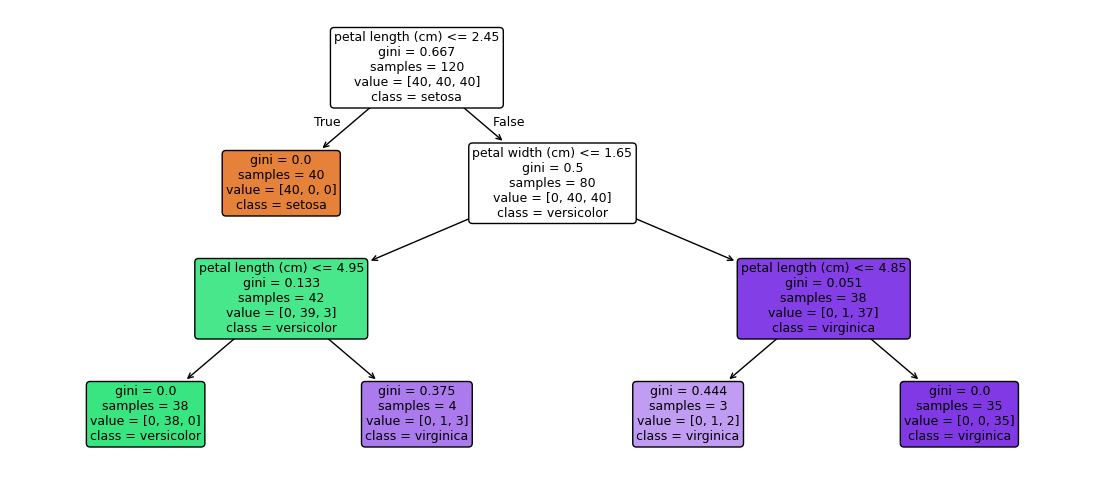

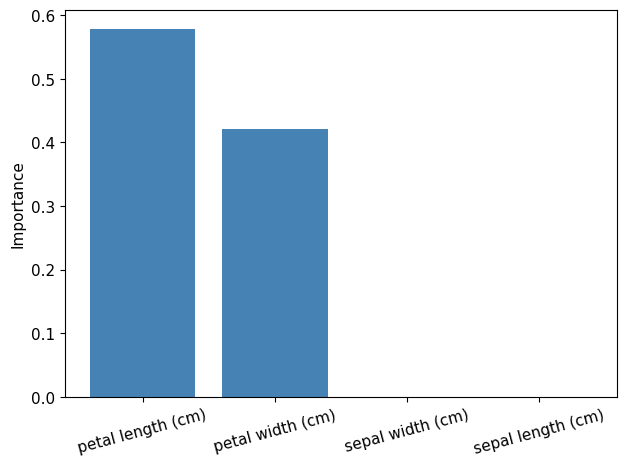

In [10]:
# ✏️ Fill in the blanks
iris = load_iris()
X_iris = pd.DataFrame(iris.data, columns=iris.feature_names)
y_iris = pd.Series(iris.target, name='species')

X_tr, X_te, y_tr, y_te = train_test_split(X_iris, y_iris, test_size=0.2, random_state=42, stratify=y_iris)

clf = DecisionTreeClassifier(max_depth=3, criterion='gini', random_state=42)
clf.fit(X_tr, y_tr)

pred = clf.predict(X_te)
print(f'Test accuracy: {accuracy_score(y_te, pred):.3f}  (one flower = {100 / len(y_te):.1f} points)')
print(confusion_matrix(y_te, pred))

fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(clf, feature_names=iris.feature_names, class_names=iris.target_names, filled=True, rounded=True, fontsize=9, ax=ax)
plt.show()

# Bar chart of feature importances, largest first
order = np.argsort(clf.feature_importances_)[::-1]
plt.bar([iris.feature_names[i] for i in order], clf.feature_importances_[order], color='steelblue')
plt.ylabel('Importance'); plt.xticks(rotation=15); plt.tight_layout(); plt.show()

**💬 Think About It:**

*Which two species did the tree mix up, if any? Does the scatter of petal sizes explain why?*  
*Which columns did the tree not use at all?*  
*One test flower equals how many accuracy points? How sure can you be of 96.7%?*

---
---
# 🛒 PART 3 — Real-Size Data: Overfitting, Brakes and the Forest
## `customer_survey.csv` — the same file from the SVM lab

On 20 people, memorising is easy to miss. On **11,805 customers with real noise**, you can see it clearly. Then you meet the cure: a forest that votes.

---

---
## ✏️ Task 6 — Watch a Tree Overfit

### Background
Load the survey, prepare it, and train trees of different depth. One split is jumpy, so **average 10 different random splits** for each depth.

What to look for:
- Training accuracy rises with depth. It can reach about 97% or more.
- Test accuracy rises, **peaks**, and then slips. That is overfitting, the same danger as KNN with K = 1 and a huge SVM gamma.

### Steps
1. Load `customer_survey.csv` with `load_csv(...)` into `survey`. Create `satisfied` (1 if "Satisfied") and `is_prime` (1 if "Prime")
2. Build `Xs` from `Region`, `Age`, `Order_Quantity`, `is_prime` and `ys` from `satisfied`
3. Write `average_scores(**tree_settings)` that trains a tree on 10 random 80/20 splits (`random_state=seed` for seed 0 to 9, `stratify=ys`) and returns the average training score, average test score and average number of leaves
4. Run it for `max_depth` from 1 to 12 and `None`. Print a table
5. Plot training and test accuracy against depth, and print the depth with the best test score

> 💡 `X_a, X_b, y_a, y_b` are the train and test parts; fit on `(X_a, y_a)` and score on `(X_b, y_b)`  
> 💡 `**tree_settings` lets you pass `max_depth=...` or `min_samples_leaf=...` straight into the tree

📂 customer_survey.csv not found — choose it in the upload box below


Saving customer_survey.csv to customer_survey.csv
 max_depth   train    test  leaves
         1   0.911   0.909       2
         2   0.942   0.942       4
         3   0.942   0.942       8
         4   0.942   0.942      15
         5   0.946   0.945      26
         6   0.947   0.945      44
         7   0.948   0.944      73
         8   0.949   0.943     113
         9   0.951   0.939     167
        10   0.953   0.939     239
        11   0.956   0.936     328
        12   0.959   0.934     431
      None   0.974   0.924     956


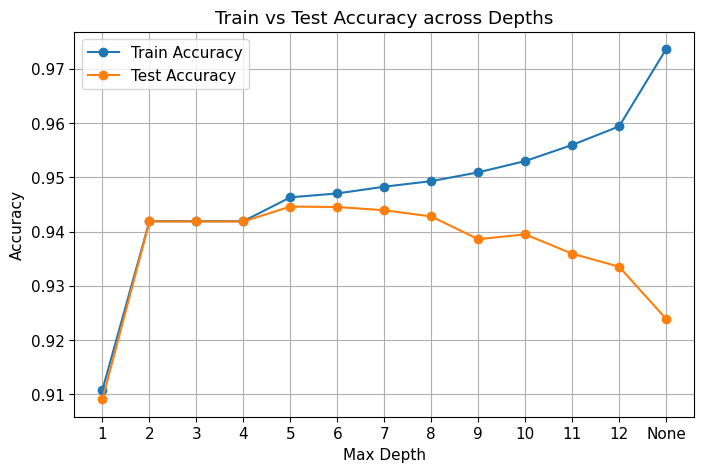

Best Test Accuracy depth (excluding None): 5 with 0.945


In [11]:
# ✏️ Fill in the blanks
survey = load_csv('customer_survey.csv')
survey['satisfied'] = (survey['Overall_Satisfaction'] == 'Satisfied').astype(int)
survey['is_prime']  = (survey['Customer_Type'] == 'Prime').astype(int)
Xs = survey[['Region', 'Age', 'Order_Quantity', 'is_prime']]
ys = survey['satisfied']

def average_scores(**tree_settings):
    """Average train score, test score and leaves over 10 random 80/20 splits."""
    tr, te, leaves = [], [], []
    for seed in range(10):
        X_a, X_b, y_a, y_b = train_test_split(Xs, ys, test_size=0.2, random_state=seed, stratify=ys)
        m = DecisionTreeClassifier(random_state=0, **tree_settings).fit(X_a, y_a)
        tr.append(m.score(X_a, y_a)); te.append(m.score(X_b, y_b)); leaves.append(m.get_n_leaves())
    return np.mean(tr), np.mean(te), np.mean(leaves)

depths = list(range(1, 13)) + [None]
rows = [average_scores(max_depth=d) for d in depths]
print(f'{"max_depth":>10} {"train":>7} {"test":>7} {"leaves":>7}')
for d, (a, b, c) in zip(depths, rows):
    print(f'{str(d):>10} {a:>7.3f} {b:>7.3f} {c:>7.0f}')

# Plot train and test accuracy against depth, then print the best depth
train_accs = [r[0] for r in rows]
test_accs = [r[1] for r in rows]

plt.figure(figsize=(8, 5))
plt.plot([str(d) for d in depths], train_accs, label='Train Accuracy', marker='o')
plt.plot([str(d) for d in depths], test_accs, label='Test Accuracy', marker='o')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.title('Train vs Test Accuracy across Depths')
plt.legend()
plt.grid(True)
plt.show()

best_idx = np.argmax(test_accs[:-1])
best_depth = depths[best_idx]
print(f'Best Test Accuracy depth (excluding None): {best_depth} with {test_accs[best_idx]:.3f}')

**💬 Think About It:**

*At what depth is the test score best? What happens to the training score at the same time?*  
*How big is the gap between the unlimited tree's training and test score?*  
*How many leaves does the unlimited tree end up with? Is that learning or memorising?*

---
## ✏️ Task 7 — Brakes on Real Data

### Background
In Task 6 you chose a depth. There is a gentler brake: **`min_samples_leaf`**. Instead of limiting how many questions in a row, it says every final box must hold at least that many customers, so no rule is built on a handful of people.

Rule of thumb from the slides: on real-sized data try `min_samples_leaf` of 5 or more.

### Steps
1. Reuse `average_scores` with `max_depth=None` and `min_samples_leaf` in `[1, 5, 20, 50, 100]`
2. Print training score, test score and number of leaves for each
3. Compare with the unlimited tree from Task 6

In [12]:
# ✏️ Fill in the blanks
print(f'{"min_samples_leaf":>16} {"train":>7} {"test":>7} {"leaves":>7}')
for leaf_size in [1, 5, 20, 50, 100]:
    a, b, c = average_scores(min_samples_leaf=leaf_size)
    print(f'{leaf_size:>16} {a:>7.3f} {b:>7.3f} {c:>7.0f}')

min_samples_leaf   train    test  leaves
               1   0.974   0.924     956
               5   0.956   0.940     459
              20   0.950   0.942     200
              50   0.948   0.944     106
             100   0.948   0.946      61


**💬 Think About It:**

*How do the number of leaves and the test score change as the brake gets stronger?*  
*Is a simpler tree always worse? Compare training and test scores.*  
*Which would you choose, and how would you decide without looking at the test set? (Next week's topic.)*

---
## ✏️ Task 8 — Ask Many Trees, Then Vote: the Random Forest

### Background
One tree is easily fooled. A **random forest** grows many different trees (each on a random crowd of people, and each question chosen from a random handful of columns) and lets them vote. `n_estimators` is the number of trees.

You will test the forest in three ways:

1. On the **tricky person**: does the answer settle as trees are added?
2. **Tree vs forest** on two real datasets, over 10 random splits: not just the average, but the **spread** too
3. **Which columns mattered** on the salary data (`feature_importances_`)

### Steps
1. Fit `RandomForestClassifier(n_estimators=n, random_state=0)` on `X`, `y` (Task 1) for `n` in `[1, 5, 100]`. Print `predict_proba` for the tricky person (order: [Not high, High])
2. For the survey data (`Xs`, `ys`) and the breast cancer data (`load_breast_cancer()`), run 10 random splits (`random_state=seed`, `stratify=y`) and compare an **unlimited single tree** with a **forest of 100 trees**. Print the mean and the spread (`np.std`) of the test accuracy
3. Fit a forest on the four salary columns (`experience`, `education`, `age`, `certifications`) and print the importance of each

> 💡 `n_estimators=n` sets how many trees vote  
> 💡 Fit on the training part `(A_tr, b_tr)` and score on the test part `(A_te, b_te)`

In [13]:
# ✏️ Fill in the blanks
# 1) The tricky person as trees are added
for n in [1, 5, 100]:
    forest = RandomForestClassifier(n_estimators=n, random_state=0).fit(X, y)
    print(f'{n:>4} trees  [Not high, High] =', forest.predict_proba(person(3, 4))[0].round(2))

# 2) Single tree vs forest on two real datasets
cancer = load_breast_cancer()
datasets = {'Customer survey': (Xs.values, ys.values), 'Breast cancer': (cancer.data, cancer.target)}
print()
print(f'{"Dataset":<16} {"single tree":>18} {"forest (100 trees)":>20}')
for name, (A, b) in datasets.items():
    tree_scores, forest_scores = [], []
    for seed in range(10):
        A_tr, A_te, b_tr, b_te = train_test_split(A, b, test_size=0.2, random_state=seed, stratify=b)
        tree_scores.append(DecisionTreeClassifier(random_state=0).fit(A_tr, b_tr).score(A_te, b_te))
        forest_scores.append(RandomForestClassifier(n_estimators=100, random_state=0).fit(A_tr, b_tr).score(A_te, b_te))
    print(f'{name:<16} {np.mean(tree_scores):.3f} ± {np.std(tree_scores):.3f}      {np.mean(forest_scores):.3f} ± {np.std(forest_scores):.3f}')

# 3) Which columns mattered? (all four salary columns)
cols = ['experience', 'education', 'age', 'certifications']
forest = RandomForestClassifier(n_estimators=100, random_state=0).fit(df[cols], y)
for c, imp in sorted(zip(cols, forest.feature_importances_), key=lambda t: -t[1]):
    print(f'  {c:<15} {imp:.3f}')

   1 trees  [Not high, High] = [1. 0.]
   5 trees  [Not high, High] = [0.6 0.4]
 100 trees  [Not high, High] = [0.52 0.48]

Dataset                 single tree   forest (100 trees)
Customer survey  0.924 ± 0.004      0.932 ± 0.005
Breast cancer    0.935 ± 0.024      0.969 ± 0.013
  age             0.462
  experience      0.350
  certifications  0.150
  education       0.038


**💬 Think About It:**

*What happens to the tricky person's answer as you add trees? What does 52% / 48% tell you?*  
*On which dataset does the forest gain more over the single tree? Does the spread shrink too?*  
*Which columns carry the most weight? Why should you be careful reading experience and age separately? (Slide 21)*

---
---
# 🌟 BONUS Tasks
Finished early? These three go further.

---

---
## ✏️ Task 9 — Boosting and the "Who Says What?" Table  ⭐ *Bonus*

### Background
A forest grows its trees **at the same time** and lets them vote. **Boosting** grows small trees **one after another**, and each new tree focuses on the mistakes of the ones before (like a tutor re-teaching what the student got wrong).

Let us ask three tree-based methods about the same person and compare with slide 24.

### Steps
1. Fit three models on `X`, `y` from Task 1: `DecisionTreeClassifier(max_depth=2, random_state=0)`, `RandomForestClassifier(n_estimators=100, random_state=0)` and `GradientBoostingClassifier(random_state=0)`
2. For each, print the chance of Not high and High for the tricky person
3. Which answers agree, and which disagree?

In [14]:
# ✏️ Fill in the blanks
models = {
    'Single tree (depth 2)':     DecisionTreeClassifier(max_depth=2, random_state=0),
    'Random forest (100 trees)': RandomForestClassifier(n_estimators=100, random_state=0),
    'Gradient boosting':         GradientBoostingClassifier(random_state=0),
}
for name, m in models.items():
    m.fit(X, y)
    chance = m.predict_proba(person(3, 4))[0]
    print(f'{name:<28} Not high {chance[0]:.0%}   High {chance[1]:.0%}')

Single tree (depth 2)        Not high 0%   High 100%
Random forest (100 trees)    Not high 52%   High 48%
Gradient boosting            Not high 0%   High 100%


**💬 Think About It:**

*Do all three methods agree? What does that tell you about a prediction you cannot check?*  
*Which method should you trust the least for this person, and why?*

---
## ✏️ Task 10 — A Tree That Predicts a Number (Diabetes)  ⭐ *Bonus*

### Background
Trees can also predict **numbers**. A `DecisionTreeRegressor` splits the same way, but each leaf predicts the **average** of its people, and the mix-up score is the squared error instead of Gini.

Diabetes: 442 patients, 10 measurements. The score to predict is how much the disease progressed after a year. The columns are already standardised, which is why thresholds look like `bmi <= 0.009`.

### Steps
1. Load the data with `load_diabetes()` into `X_reg` (a DataFrame) and `y_reg`
2. Split 80/20 with `random_state=42`
3. Train `DecisionTreeRegressor(max_depth=3, random_state=42)` and print RMSE and R² on the test set
4. Loop `max_depth` from 1 to 14, record train and test R², and plot both. Where does the test R² peak?

RMSE: 59.6   R²: 0.329


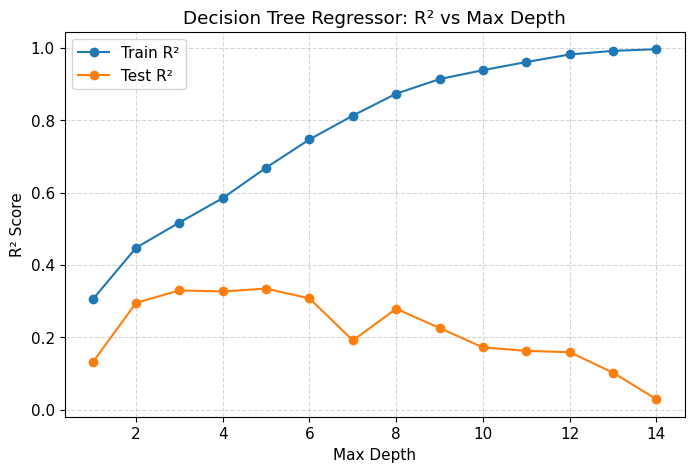

Best Test R² depth: 5 with R² = 0.334


In [18]:
# ✏️ Fill in the blanks
diabetes = load_diabetes()
X_reg = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
y_reg = pd.Series(diabetes.target)

X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

reg = DecisionTreeRegressor(max_depth=3, random_state=42).fit(X_tr_r, y_tr_r)
pred = reg.predict(X_te_r)
print(f'RMSE: {np.sqrt(mean_squared_error(y_te_r, pred)):.1f}   R²: {r2_score(y_te_r, pred):.3f}')

depths = range(1, 15)
train_r2, test_r2 = [], []
for d in depths:
    m = DecisionTreeRegressor(max_depth=d, random_state=42).fit(X_tr_r, y_tr_r)
    train_r2.append(r2_score(y_tr_r, m.predict(X_tr_r)))
    test_r2.append(r2_score(y_te_r, m.predict(X_te_r)))

# plot train and test R² against depth, and print the best depth
plt.figure(figsize=(8, 5))
plt.plot(depths, train_r2, label='Train R²', marker='o')
plt.plot(depths, test_r2, label='Test R²', marker='o')
plt.xlabel('Max Depth')
plt.ylabel('R² Score')
plt.title('Decision Tree Regressor: R² vs Max Depth')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

best_d_idx = np.argmax(test_r2)
print(f'Best Test R² depth: {depths[best_d_idx]} with R² = {test_r2[best_d_idx]:.3f}')

**💬 Think About It:**

*Is R² of about 0.3 good for medical data? What does 0.3 mean?*  
*Is the curve smooth? With only 89 test patients, how much should you trust one peak?*

---
## ✏️ Task 11 — Pruning: Grow Big, Then Cut Back  ⭐ *Bonus*

### Background
Slide 14 mentioned a third brake: **pruning**. Instead of stopping early, grow the big tree, then cut off branches that add very little. In scikit-learn this is `ccp_alpha`: the bigger it is, the more branches are cut.

### Steps
1. Reuse `average_scores` from Task 6 with `ccp_alpha` in `[0, 0.0001, 0.0002, 0.0005, 0.001]`
2. Print training score, test score and number of leaves for each
3. Compare with the unlimited tree (`ccp_alpha = 0`)

In [22]:
# ✏️ Fill in the blanks
print(f'{"ccp_alpha":>10} {"train":>7} {"test":>7} {"leaves":>7}')
for alpha in [0, 0.0001, 0.0002, 0.0005, 0.001]:
    a, b, c = average_scores(ccp_alpha=alpha)
    print(f'{alpha:>10g} {a:>7.3f} {b:>7.3f} {c:>7.0f}')

 ccp_alpha   train    test  leaves
         0   0.974   0.924     956
    0.0001   0.955   0.941      72
    0.0002   0.948   0.945      11
    0.0005   0.946   0.945       6
     0.001   0.946   0.945       6


**💬 Think About It:**

*How many leaves does a tiny `ccp_alpha` cut away? What happens to the test score?*  
*Which brake would you reach for first on real data: `max_depth`, `min_samples_leaf` or pruning? Why?*

---
## ✏️ Task 12 — Entropy and Information Gain: Another Way to Score a Question  ⭐ *Bonus*

### Background
Task 2 scored a question with **Gini**. The older ID3 algorithm used **entropy** instead. It also measures how mixed a group is:

```
Entropy = −p(High) × log2 p(High) − p(Not high) × log2 p(Not high)
```

0 means a pure group, 1 means a perfect 50-50 mix. Instead of "average mix-up after the split" (lower is better), ID3 reports **information gain = entropy before − average entropy after** (bigger is better). scikit-learn offers both: `criterion='gini'` (default) or `criterion='entropy'`.

### Steps
1. Write `entropy(n_high, n_not)`. Handle a group with no High (or no Not high): that term counts as 0
2. Print the entropy of all 20 people, of 9 people who are all High, and of 6 High + 6 Not high
3. Write `info_gain(column, cut)` using the same `df` and `y` as Task 2
4. Print the gain for the three questions from slide 8 and compare the winner with Gini
5. Grow a depth-1 tree with `criterion='entropy'` and check that it picks the same first question

> 💡 `np.log2(p)` is the base-2 logarithm  
> 💡 `0 × log2(0)` is undefined, which is why the `if n > 0` check is there

In [23]:
# ✏️ Fill in the blanks
def entropy(n_high, n_not):
    total = n_high + n_not
    result = 0
    for n in (n_high, n_not):
        if n > 0:
            p = n / total
            result -= p * np.log2(p)
    return result

print('All 20 people      :', round(entropy(11, 9), 3))
print('9 people, all High :', round(entropy(9, 0), 3))
print('6 High, 6 Not high :', round(entropy(6, 6), 3))

def info_gain(column, cut):
    left = df[column] <= cut
    n_left, n_right = left.sum(), (~left).sum()
    e_left  = entropy(y[left].sum(), (1 - y[left]).sum())
    e_right = entropy(y[~left].sum(), (1 - y[~left]).sum())
    after = (n_left * e_left + n_right * e_right) / len(df)
    return entropy(y.sum(), (1 - y).sum()) - after

for column, cut in [('experience', 3.5), ('experience', 5.5), ('certifications', 2.5)]:
    print(f'{column} <= {cut}: gain {info_gain(column, cut):.3f}')

stump = DecisionTreeClassifier(criterion='entropy', max_depth=1, random_state=42).fit(df[['experience', 'certifications']], y)
print('Entropy tree asks: ', export_text(stump, feature_names=['experience', 'certifications']).splitlines()[0])

All 20 people      : 0.993
9 people, all High : 0.0
6 High, 6 Not high : 1.0
experience <= 3.5: gain 0.590
experience <= 5.5: gain 0.617
certifications <= 2.5: gain 0.335
Entropy tree asks:  |--- experience <= 5.50


**💬 Think About It:**

*Do entropy and Gini pick the same first question here? Do they always have to?*  
*Gini wants a low number after the split, information gain wants a high one. Why is that not a contradiction?*

---
## 📝 Final Reflection

*There are no right or wrong answers — think it through and write your answers below.*

---

**Q1 — Gini:**  
What does a Gini score of 0 mean? Why does the tree try to make the groups' Gini small at every question?

**Q2 — Memorising:**  
In Task 4 the unlimited tree scored 100% on the 20 people, and in Task 6 the unlimited tree scored lower on new customers than a shallower tree. What happened? Name two other methods from this week that can memorise in the same way.

**Q3 — The brakes:**  
In Task 4, `min_samples_leaf` changed the answer for the tricky person. Is the new answer more trustworthy? Why?

**Q4 — Forest:**  
In Task 8, why does a vote among many different trees help? On which dataset was the gain bigger, and did the spread shrink too?

**Q5 — Choosing:**  
A bank must explain every decision to its customers. Would you give it a single tree or a forest? What would you give up? (Slide 25, Exercise 5.)

**Your answers:**

Q1:

Q2:

Q3:

Q4:

Q5:

---
## 🗺️ What You Covered

```
💼 Salary data  (Tasks 1–4)
   Task 1  →  Label the 20 people and draw them
   Task 2  →  Gini by hand: find the best first question
   Task 3  →  Grow a depth-2 tree and follow the boxes
   Task 4  →  A tree that never stops memorises; the first brake

🌸 Iris  (Task 5)
   Task 5  →  Read a real tree and rank the columns

🛒 Real-size data  (Tasks 6–8)
   Task 6  →  Watch a tree overfit
   Task 7  →  Brakes on real data (min_samples_leaf)
   Task 8  →  The forest: many trees, one vote

🌟 Bonus
   Task 9  →  Boosting and "who says what?"
   Task 10 →  A tree that predicts a number (Diabetes)
   Task 11 →  Pruning with ccp_alpha
   Task 12 →  Entropy and information gain (the ID3 score)
```

---
*🎓 Well done! Next week: how to measure which model is really better on people it has never seen (model evaluation).*